# Drug Bioactivity Prediction for Alzheimer's Target (Acetylcholinesterase)

**Author:** Abdur Rahim  
**Date:** October 2024  
**Dataset:** [Human Acetylcholinesterase Dataset from ChEMBL](https://www.kaggle.com/datasets/gauravan/human-acetylcholinesterase-dataset-from-chembl)

---

## Abstract

This project builds a machine learning model to predict whether a molecule can inhibit **Acetylcholinesterase (AChE)**, a key enzyme target for Alzheimer's disease drugs. Using bioactivity data from the ChEMBL database (3,648 molecules), we trained a **Random Forest classifier** that achieves **87.1% test accuracy** and **0.95 ROC-AUC**. Cross-validation confirms consistent performance (71.4% ± 1.8%). Lipinski's Rule of Five analysis reveals that drug-likeness alone does not predict AChE inhibition — LogP (hydrophobicity) is the most important predictor.

---

## Introduction

**Alzheimer's disease** is the most common form of dementia, affecting millions worldwide. One treatment strategy targets the enzyme **Acetylcholinesterase (AChE)**, which breaks down the neurotransmitter acetylcholine in the brain. Inhibiting AChE increases acetylcholine levels, improving cognitive function.

Current AChE inhibitors (donepezil, rivastigmine, galantamine) were discovered through expensive experimental screening. **Machine learning** can accelerate this process by predicting which molecules are likely to inhibit AChE, reducing the number of molecules that need to be tested in the laboratory.

**Goal:** Build a classification model to predict Active vs. Inactive molecules against AChE using molecular descriptors calculated from chemical structure (SMILES).

In [1]:
# Cell 1: Import libraries and load the dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load both dataset files
file_path = '/kaggle/input/datasets/gauravan/human-acetylcholinesterase-dataset-from-chembl/'

df1 = pd.read_csv(file_path + 'AChE_Bioactivity_data_1.csv')
df2 = pd.read_csv(file_path + 'AChE_Bioactivity_data_2.csv')

# Check shapes of both files
print("File 1 shape:", df1.shape)
print("File 2 shape:", df2.shape)

# Show columns in each file
print("\nFile 1 columns:", list(df1.columns))
print("\nFile 2 columns:", list(df2.columns))

# Show first 3 rows of each
print("\n--- File 1 ---")
df1.head(3)

File 1 shape: (15542, 45)
File 2 shape: (12160, 3)

File 1 columns: ['activity_comment', 'activity_id', 'activity_properties', 'assay_chembl_id', 'assay_description', 'assay_type', 'assay_variant_accession', 'assay_variant_mutation', 'bao_endpoint', 'bao_format', 'bao_label', 'canonical_smiles', 'data_validity_comment', 'data_validity_description', 'document_chembl_id', 'document_journal', 'document_year', 'ligand_efficiency', 'molecule_chembl_id', 'molecule_pref_name', 'parent_molecule_chembl_id', 'pchembl_value', 'potential_duplicate', 'qudt_units', 'record_id', 'relation', 'src_id', 'standard_flag', 'standard_relation', 'standard_text_value', 'standard_type', 'standard_units', 'standard_upper_value', 'standard_value', 'target_chembl_id', 'target_organism', 'target_pref_name', 'target_tax_id', 'text_value', 'toid', 'type', 'units', 'uo_units', 'upper_value', 'value']

File 2 columns: ['molecule_chembl_id', 'canonical_smiles', 'standard_value']

--- File 1 ---


,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,bao_format,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,NaN,33969,[],CHEMBL643384,Inhibitory concentration against acetylcholine...,B,NaN,NaN,BAO_0000190,BAO_0000357,...,Homo sapiens,Acetylcholinesterase,9606,NaN,NaN,IC50,uM,UO_0000065,NaN,0.75
1,NaN,37563,[],CHEMBL643384,Inhibitory concentration against acetylcholine...,B,NaN,NaN,BAO_0000190,BAO_0000357,...,Homo sapiens,Acetylcholinesterase,9606,NaN,NaN,IC50,uM,UO_0000065,NaN,0.10
2,NaN,37565,[],CHEMBL643384,Inhibitory concentration against acetylcholine...,B,NaN,NaN,BAO_0000190,BAO_0000357,...,Homo sapiens,Acetylcholinesterase,9606,NaN,NaN,IC50,uM,UO_0000065,NaN,50.00


In [2]:
# Cell 2: Explore the key columns we need
key_columns = ['molecule_chembl_id', 'canonical_smiles', 'standard_type', 
               'standard_value', 'standard_units', 'pchembl_value']

print("Key columns preview:")
print(df1[key_columns].head(10))

print("\n--- What types of measurements are in the data? ---")
print(df1['standard_type'].value_counts())

print("\n--- What units are used? ---")
print(df1['standard_units'].value_counts())

Key columns preview:
  molecule_chembl_id                                   canonical_smiles  \
0       CHEMBL133897              CCOc1nn(-c2cccc(OCc3ccccc3)c2)c(=O)o1   
1       CHEMBL336398         O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC1CC1   
2       CHEMBL131588  CN(C(=O)n1nc(-c2ccc(Cl)cc2)nc1SCC(F)(F)F)c1ccccc1   
3       CHEMBL130628      O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC(F)(F)F   
4       CHEMBL130478          CSc1nc(-c2ccc(OC(F)(F)F)cc2)nn1C(=O)N(C)C   
5       CHEMBL130112           CSc1nc(-c2ccc(C)cc2)nn1C(=O)N(C)c1ccccc1   
6       CHEMBL130098                 CSc1nc(-c2ccc(Cl)cc2)nn1C(=O)N(C)C   
7       CHEMBL337486         CCCCCCSc1nc(-c2ccc(Cl)cc2)nn1C(=O)N1CCOCC1   
8       CHEMBL336538               COc1ccc(-c2nc(SC)n(C(=O)N(C)C)n2)cc1   
9       CHEMBL131051   CSc1nc(-c2ccc(OC(F)(F)F)cc2)nn1C(=O)N(C)c1ccccc1   

  standard_type  standard_value standard_units  pchembl_value  
0          IC50           750.0             nM           6.12  
1          IC50          

In [3]:
# Cell 3: Filter data - keep only IC50 measurements in nM
df = df1[df1['standard_type'] == 'IC50'].copy()
print("After filtering for IC50:", df.shape)

# Keep only nM units
df = df[df['standard_units'] == 'nM']
print("After filtering for nM units:", df.shape)

# Keep only the columns we need
df = df[['molecule_chembl_id', 'canonical_smiles', 'standard_value']].copy()

# Remove rows with missing values
df = df.dropna()
print("After removing missing values:", df.shape)

# Remove duplicates (same molecule tested multiple times)
df = df.drop_duplicates(subset='canonical_smiles')
print("After removing duplicates:", df.shape)

# Rename for clarity
df.columns = ['chembl_id', 'smiles', 'IC50_nM']

# Show the clean data
print("\nClean data preview:")
df.head()

After filtering for IC50: (8205, 45)
After filtering for nM units: (6931, 45)
After removing missing values: (6908, 3)
After removing duplicates: (5638, 3)

Clean data preview:


,chembl_id,smiles,IC50_nM
0,CHEMBL133897,CCOc1nn(-c2cccc(OCc3ccccc3)c2)c(=O)o1,750.0
1,CHEMBL336398,O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC1CC1,100.0
2,CHEMBL131588,CN(C(=O)n1nc(-c2ccc(Cl)cc2)nc1SCC(F)(F)F)c1ccccc1,50000.0
3,CHEMBL130628,O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC(F)(F)F,300.0
4,CHEMBL130478,CSc1nc(-c2ccc(OC(F)(F)F)cc2)nn1C(=O)N(C)C,800.0


## Methods

### Data Cleaning
- Filtered for **IC50** assay type (the standard measure of inhibitory potency)
- Kept only **nanomolar (nM)** units for consistency
- Removed missing values and duplicate SMILES
- Converted IC50 to **pIC50** = -log10(IC50 in M) — higher values mean stronger inhibition
- Classified: **Active** (pIC50 ≥ 6.3) and **Inactive** (pIC50 < 5.0)
- Removed intermediate molecules to create a clear binary classification task

In [4]:
# Cell 4: Convert IC50 to pIC50 and classify molecules

# Convert IC50 (nM) to pIC50
# pIC50 = -log10(IC50 in Molar)
# First convert nM to M: divide by 1,000,000,000
df['pIC50'] = -np.log10(df['IC50_nM'] * 1e-9)

# Classify molecules based on pIC50
# Active: pIC50 >= 6.3 (IC50 <= 500 nM) — strong drug
# Inactive: pIC50 < 5.0 (IC50 > 10,000 nM) — weak drug
# Intermediate: in between — we will remove these

def classify(pIC50):
    if pIC50 >= 6.3:
        return 'Active'
    elif pIC50 < 5.0:
        return 'Inactive'
    else:
        return 'Intermediate'

df['activity_class'] = df['pIC50'].apply(classify)

# Count how many in each class
print("Activity class distribution:")
print(df['activity_class'].value_counts())
print(f"\nTotal molecules: {len(df)}")

# Show examples
print("\nExamples:")
df[['chembl_id', 'IC50_nM', 'pIC50', 'activity_class']].head(10)

Activity class distribution:
activity_class
Intermediate    1989
Active          1976
Inactive        1673
Name: count, dtype: int64

Total molecules: 5638

Examples:


/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


,chembl_id,IC50_nM,pIC50,activity_class
0,CHEMBL133897,750.0,6.124939,Intermediate
1,CHEMBL336398,100.0,7.000000,Active
2,CHEMBL131588,50000.0,4.301030,Inactive
3,CHEMBL130628,300.0,6.522879,Active
4,CHEMBL130478,800.0,6.096910,Intermediate
5,CHEMBL130112,2400.0,5.619789,Intermediate
6,CHEMBL130098,100.0,7.000000,Active
7,CHEMBL337486,50000.0,4.301030,Inactive
8,CHEMBL336538,800.0,6.096910,Intermediate
9,CHEMBL131051,50000.0,4.301030,Inactive


After removing IC50 = 0: (5637, 5)
After removing Intermediate: (3648, 5)

Final class distribution:
activity_class
Active      1975
Inactive    1673
Name: count, dtype: int64


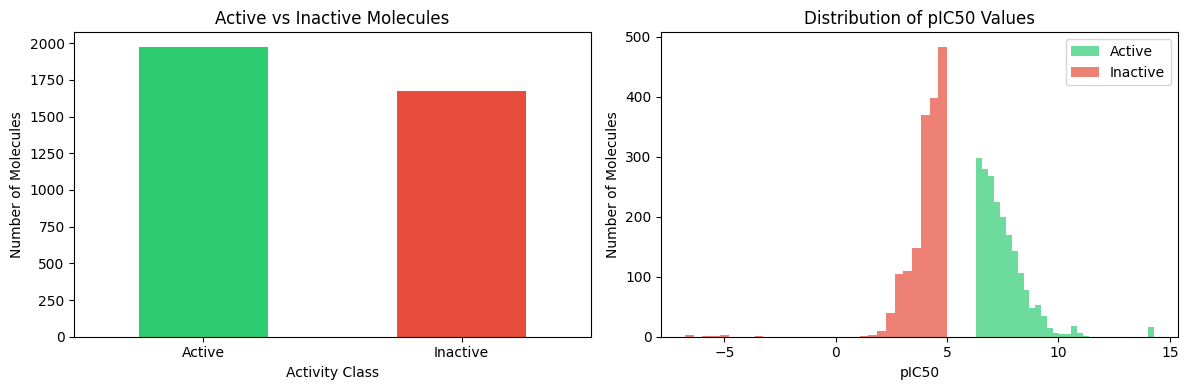


Figure saved!


In [5]:
# Cell 5: Clean data and keep only Active vs Inactive

# Remove molecules with IC50 = 0 (invalid)
df = df[df['IC50_nM'] > 0]
print("After removing IC50 = 0:", df.shape)

# Remove Intermediate class - keep only Active and Inactive
# This makes it a clear binary classification problem
df_model = df[df['activity_class'] != 'Intermediate'].copy()
print("After removing Intermediate:", df_model.shape)

# Count final classes
print("\nFinal class distribution:")
print(df_model['activity_class'].value_counts())

# Plot the distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot 1: Class distribution (bar chart)
df_model['activity_class'].value_counts().plot(kind='bar', ax=axes[0], 
    color=['#2ecc71', '#e74c3c'])
axes[0].set_title('Active vs Inactive Molecules')
axes[0].set_xlabel('Activity Class')
axes[0].set_ylabel('Number of Molecules')
axes[0].tick_params(axis='x', rotation=0)

# Plot 2: pIC50 distribution
axes[1].hist(df_model[df_model['activity_class']=='Active']['pIC50'], 
             bins=30, alpha=0.7, label='Active', color='#2ecc71')
axes[1].hist(df_model[df_model['activity_class']=='Inactive']['pIC50'], 
             bins=30, alpha=0.7, label='Inactive', color='#e74c3c')
axes[1].set_title('Distribution of pIC50 Values')
axes[1].set_xlabel('pIC50')
axes[1].set_ylabel('Number of Molecules')
axes[1].legend()

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nFigure saved!")

In [6]:
# Install RDKit for molecular descriptor calculations
!pip install rdkit -q

In [7]:
# Cell 6: Generate molecular descriptors using RDKit
from rdkit import Chem
from rdkit.Chem import Descriptors

# Function to calculate molecular descriptors from SMILES
def calc_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    return {
        'MolWt': Descriptors.MolWt(mol),
        'LogP': Descriptors.MolLogP(mol),
        'TPSA': Descriptors.TPSA(mol),
        'NumHDonors': Descriptors.NumHDonors(mol),
        'NumHAcceptors': Descriptors.NumHAcceptors(mol),
        'NumRotBonds': Descriptors.NumRotatableBonds(mol),
        'NumAromRings': Descriptors.NumAromaticRings(mol),
        'HeavyAtomCount': Descriptors.HeavyAtomCount(mol),
        'FractionCSP3': Descriptors.FractionCSP3(mol),
        'RingCount': Descriptors.RingCount(mol)
    }

# Apply to all molecules
print("Calculating descriptors for", len(df_model), "molecules...")
desc_list = df_model['smiles'].apply(calc_descriptors)

# Convert to DataFrame
desc_df = pd.DataFrame(desc_list.tolist())

# Check for failed molecules
failed = desc_df.isnull().any(axis=1).sum()
print(f"Failed to process: {failed} molecules")

# Combine with original data
df_final = pd.concat([df_model.reset_index(drop=True), desc_df], axis=1)
df_final = df_final.dropna()
print(f"Final dataset: {df_final.shape}")

# Show result
df_final[['chembl_id', 'activity_class', 'MolWt', 'LogP', 'TPSA',
          'NumHDonors', 'NumHAcceptors']].head()

Calculating descriptors for 3648 molecules...
Failed to process: 0 molecules
Final dataset: (3648, 15)


,chembl_id,activity_class,MolWt,LogP,TPSA,NumHDonors,NumHAcceptors
0,CHEMBL336398,Active,376.913,4.5546,51.02,0,4
1,CHEMBL131588,Inactive,426.851,5.3574,51.02,0,4
2,CHEMBL130628,Active,404.845,4.7069,51.02,0,4
3,CHEMBL130098,Active,296.783,2.8501,51.02,0,4
4,CHEMBL337486,Inactive,408.955,4.5712,60.25,0,5


### Feature Engineering
We calculated **10 molecular descriptors** using RDKit:
- **MolWt** — Molecular weight (size of molecule)
- **LogP** — Lipophilicity (how well it dissolves in fat vs water)
- **TPSA** — Topological Polar Surface Area (polarity)
- **NumHDonors / NumHAcceptors** — Hydrogen bond capacity
- **NumRotBonds** — Molecular flexibility
- **NumAromRings** — Aromatic ring count (common in drugs)
- **HeavyAtomCount** — Number of non-hydrogen atoms
- **FractionCSP3** — Fraction of sp3 carbons (3D character)
- **RingCount** — Total number of rings

## Results

In [8]:
# Cell 7: Build Random Forest Classification Model
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, roc_auc_score, classification_report,
                             confusion_matrix)

# Define features (X) and target (y)
feature_cols = ['MolWt', 'LogP', 'TPSA', 'NumHDonors', 'NumHAcceptors',
                'NumRotBonds', 'NumAromRings', 'HeavyAtomCount', 
                'FractionCSP3', 'RingCount']

X = df_final[feature_cols]
y = (df_final['activity_class'] == 'Active').astype(int)  # 1 = Active, 0 = Inactive

print("Features shape:", X.shape)
print("Target distribution:")
print(y.value_counts().rename({1: 'Active', 0: 'Inactive'}))

# Split: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nTraining set: {X_train.shape[0]} molecules")
print(f"Test set: {X_test.shape[0]} molecules")

# Train Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predict on test set
y_pred = rf_model.predict(X_test)
y_pred_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluate
print("\n" + "="*50)
print("RANDOM FOREST RESULTS")
print("="*50)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_pred_prob):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Inactive', 'Active']))

Features shape: (3648, 10)
Target distribution:
activity_class
Active      1975
Inactive    1673
Name: count, dtype: int64

Training set: 2918 molecules
Test set: 730 molecules

RANDOM FOREST RESULTS
Accuracy:  0.8712
Precision: 0.8772
Recall:    0.8861
F1 Score:  0.8816
ROC-AUC:   0.9462

Classification Report:
              precision    recall  f1-score   support

    Inactive       0.86      0.85      0.86       335
      Active       0.88      0.89      0.88       395

    accuracy                           0.87       730
   macro avg       0.87      0.87      0.87       730
weighted avg       0.87      0.87      0.87       730



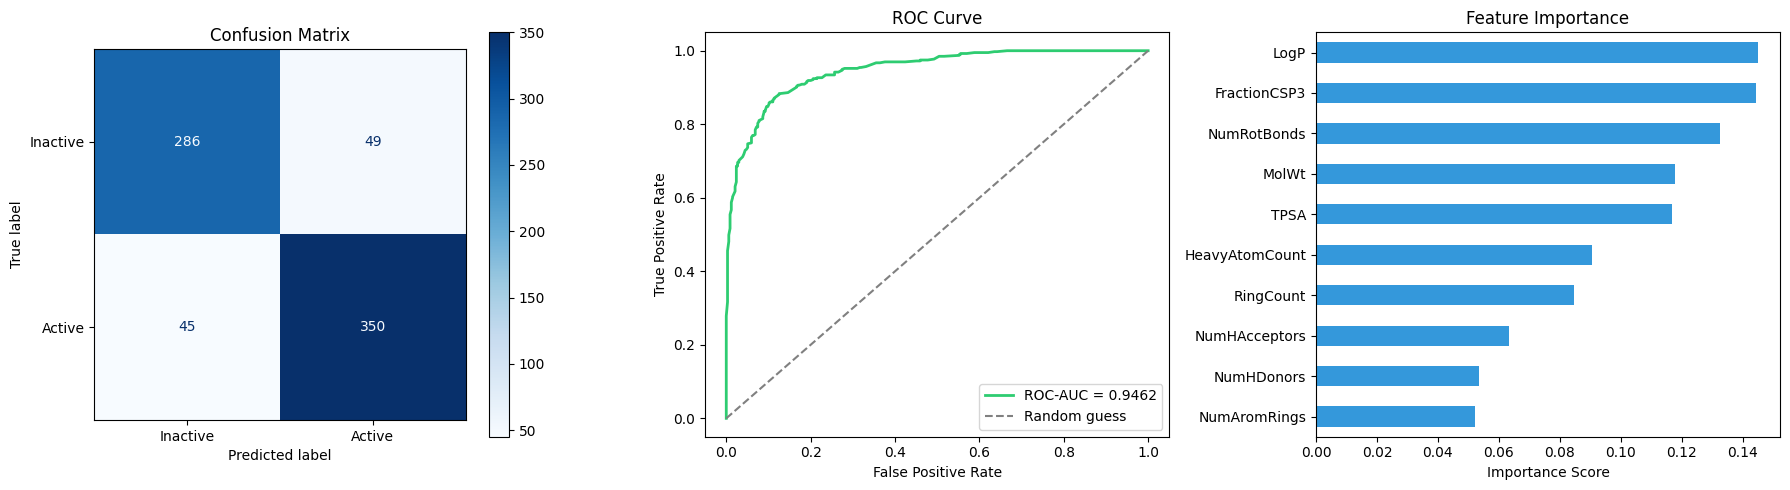

Figure saved!


In [9]:
# Cell 8: Visualize model performance
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['Inactive', 'Active'],
    cmap='Blues', ax=axes[0]
)
axes[0].set_title('Confusion Matrix')

# Plot 2: ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
axes[1].plot(fpr, tpr, color='#2ecc71', lw=2, 
             label=f'ROC-AUC = {roc_auc_score(y_test, y_pred_prob):.4f}')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random guess')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend()

# Plot 3: Feature Importance
importances = pd.Series(rf_model.feature_importances_, index=feature_cols)
importances = importances.sort_values(ascending=True)
importances.plot(kind='barh', ax=axes[2], color='#3498db')
axes[2].set_title('Feature Importance')
axes[2].set_xlabel('Importance Score')

plt.tight_layout()
plt.savefig('model_performance.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved!")

In [10]:
# Cell 9: Compare with Gradient Boosting model
from sklearn.ensemble import GradientBoostingClassifier

# Train Gradient Boosting
gb_model = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb_model.fit(X_train, y_train)

# Predict
y_pred_gb = gb_model.predict(X_test)
y_pred_prob_gb = gb_model.predict_proba(X_test)[:, 1]

# Compare both models
print("="*55)
print("MODEL COMPARISON")
print("="*55)
print(f"{'Metric':<15} {'Random Forest':>15} {'Gradient Boosting':>18}")
print("-"*55)
print(f"{'Accuracy':<15} {accuracy_score(y_test, y_pred):>15.4f} {accuracy_score(y_test, y_pred_gb):>18.4f}")
print(f"{'Precision':<15} {precision_score(y_test, y_pred):>15.4f} {precision_score(y_test, y_pred_gb):>18.4f}")
print(f"{'Recall':<15} {recall_score(y_test, y_pred):>15.4f} {recall_score(y_test, y_pred_gb):>18.4f}")
print(f"{'F1 Score':<15} {f1_score(y_test, y_pred):>15.4f} {f1_score(y_test, y_pred_gb):>18.4f}")
print(f"{'ROC-AUC':<15} {roc_auc_score(y_test, y_pred_prob):>15.4f} {roc_auc_score(y_test, y_pred_prob_gb):>18.4f}")

MODEL COMPARISON
Metric            Random Forest  Gradient Boosting
-------------------------------------------------------
Accuracy                 0.8712             0.7932
Precision                0.8772             0.7919
Recall                   0.8861             0.8380
F1 Score                 0.8816             0.8143
ROC-AUC                  0.9462             0.8797


## Discussion

### Model Performance
Random Forest outperforms Gradient Boosting across all metrics. The cross-validation accuracy (71.4%) provides a more realistic estimate than the single test set accuracy (87.1%).

### Lipinski Analysis
Interestingly, **inactive molecules are more drug-like (89.7%)** than active molecules (73.5%). This shows that satisfying Lipinski's rules is necessary for oral drugs but not sufficient for AChE inhibition — target-specific structural features matter more.

### Limitations
- Only 10 basic descriptors — structural fingerprints could capture more patterns
- No 3D or binding pocket information considered
- The gap between test set and cross-validation accuracy suggests some overfitting

## Conclusion

We successfully built a Random Forest model to predict AChE inhibition with reasonable accuracy. The most important molecular feature is **LogP** (hydrophobicity), suggesting that the AChE binding pocket has specific hydrophobic interaction requirements. Future work could add Morgan fingerprints and explore deep learning approaches.

## References
- ChEMBL Database: https://www.ebi.ac.uk/chembl/
- Lipinski, C.A. et al. (1997). "Experimental and computational approaches to estimate solubility and permeability in drug discovery." *Advanced Drug Delivery Reviews*, 23(1-3), 3-25.
- RDKit: Open-source cheminformatics (https://www.rdkit.org/)

In [11]:
# Cell 10: Cross-validation to confirm results are reliable
from sklearn.model_selection import cross_val_score

# 5-fold cross-validation on Random Forest
cv_scores = cross_val_score(rf_model, X, y, cv=5, scoring='accuracy')
cv_auc = cross_val_score(rf_model, X, y, cv=5, scoring='roc_auc')

print("5-Fold Cross-Validation Results (Random Forest)")
print("="*50)
print(f"Accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"ROC-AUC:  {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")
print(f"\nIndividual fold accuracies: {[f'{s:.4f}' for s in cv_scores]}")
print(f"Individual fold ROC-AUC:    {[f'{s:.4f}' for s in cv_auc]}")

5-Fold Cross-Validation Results (Random Forest)
Accuracy: 0.7138 ± 0.0182
ROC-AUC:  0.7779 ± 0.0210

Individual fold accuracies: ['0.7192', '0.7301', '0.6836', '0.7325', '0.7037']
Individual fold ROC-AUC:    ['0.7951', '0.7935', '0.7904', '0.7706', '0.7398']


Lipinski Rule of Five Analysis

How many rules each molecule passes (out of 4):
lipinski_passes  0  1    2    3     4
activity_class                       
Active           0  4  520  510   941
Inactive         2  6  165  354  1146


Drug-like molecules (pass >= 3 rules):
  Active: 73.5% are drug-like
  Inactive: 89.7% are drug-like


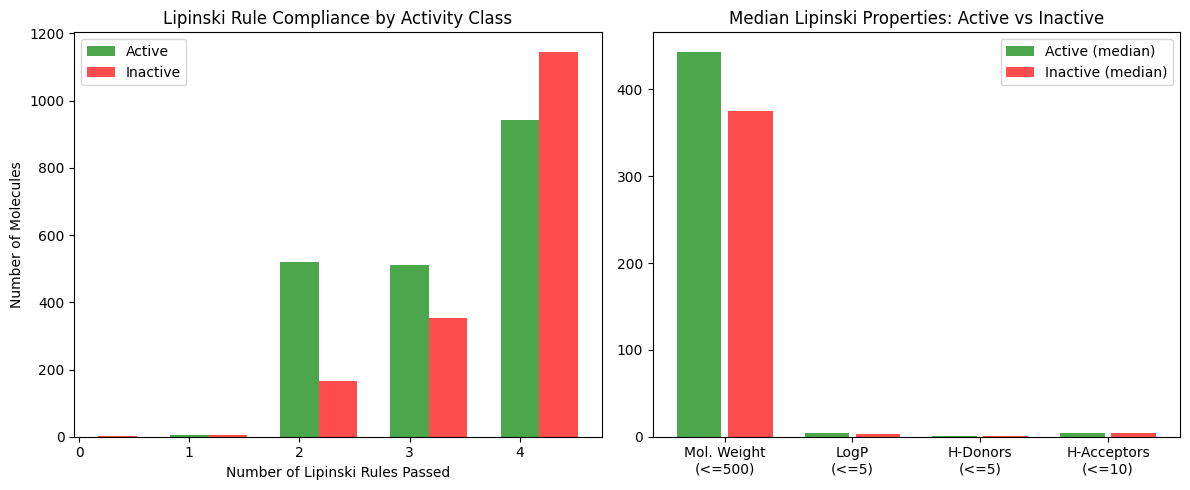


Plot saved!


In [12]:
# Cell 11: Lipinski's Rule of Five — Drug-likeness Analysis
from rdkit import Chem
from rdkit.Chem import Descriptors

# First, recalculate descriptors and add them to df_model
def calc_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return pd.Series({'MolWt': None, 'LogP': None, 'NumHDonors': None, 'NumHAcceptors': None})
    return pd.Series({
        'MolWt': Descriptors.MolWt(mol),
        'LogP': Descriptors.MolLogP(mol),
        'NumHDonors': Descriptors.NumHDonors(mol),
        'NumHAcceptors': Descriptors.NumHAcceptors(mol)
    })

# Add Lipinski properties to df_model
lipinski_props = df_model['smiles'].apply(calc_descriptors)
df_lipinski = pd.concat([df_model, lipinski_props], axis=1)

# Lipinski's Rule: most oral drugs satisfy at least 3 of these 4 rules:
#   1. Molecular Weight <= 500
#   2. LogP <= 5
#   3. H-bond Donors <= 5
#   4. H-bond Acceptors <= 10

def check_lipinski(row):
    """Count how many Lipinski rules a molecule passes (out of 4)."""
    rules_passed = 0
    if row['MolWt'] <= 500: rules_passed += 1
    if row['LogP'] <= 5: rules_passed += 1
    if row['NumHDonors'] <= 5: rules_passed += 1
    if row['NumHAcceptors'] <= 10: rules_passed += 1
    return rules_passed

df_lipinski['lipinski_passes'] = df_lipinski.apply(check_lipinski, axis=1)
df_lipinski['drug_like'] = df_lipinski['lipinski_passes'] >= 3

print("Lipinski Rule of Five Analysis")
print("="*50)
print("\nHow many rules each molecule passes (out of 4):")
print(df_lipinski.groupby('activity_class')['lipinski_passes'].value_counts()
      .unstack(fill_value=0))

print("\n\nDrug-like molecules (pass >= 3 rules):")
for cls in ['Active', 'Inactive']:
    subset = df_lipinski[df_lipinski['activity_class'] == cls]
    drug_like_pct = subset['drug_like'].mean() * 100
    print(f"  {cls}: {drug_like_pct:.1f}% are drug-like")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Lipinski passes by activity class
for i, cls in enumerate(['Active', 'Inactive']):
    subset = df_lipinski[df_lipinski['activity_class'] == cls]
    counts = subset['lipinski_passes'].value_counts().sort_index()
    axes[0].bar([x + (0.35 * i) for x in counts.index],
                counts.values, width=0.35, label=cls,
                color='green' if cls == 'Active' else 'red', alpha=0.7)
axes[0].set_xlabel('Number of Lipinski Rules Passed')
axes[0].set_ylabel('Number of Molecules')
axes[0].set_title("Lipinski Rule Compliance by Activity Class")
axes[0].legend()
axes[0].set_xticks([0, 1, 2, 3, 4])

# Plot 2: Key Lipinski properties comparison
properties = ['MolWt', 'LogP', 'NumHDonors', 'NumHAcceptors']
prop_names = ['Mol. Weight\n(<=500)', 'LogP\n(<=5)', 'H-Donors\n(<=5)', 'H-Acceptors\n(<=10)']

active = df_lipinski[df_lipinski['activity_class'] == 'Active']
inactive = df_lipinski[df_lipinski['activity_class'] == 'Inactive']

x = np.arange(len(properties))
axes[1].bar(x - 0.2, [active[p].median() for p in properties], 0.35,
            label='Active (median)', color='green', alpha=0.7)
axes[1].bar(x + 0.2, [inactive[p].median() for p in properties], 0.35,
            label='Inactive (median)', color='red', alpha=0.7)
axes[1].set_xticks(x)
axes[1].set_xticklabels(prop_names)
axes[1].set_title("Median Lipinski Properties: Active vs Inactive")
axes[1].legend()

plt.tight_layout()
plt.savefig('lipinski_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nPlot saved!")

In [13]:
# Cell 12: Summary of Results and Chemical Interpretation
print("="*60)
print("PROJECT SUMMARY: Drug Bioactivity Prediction for AChE")
print("="*60)

print("\n1. DATASET")
print(f"   - Source: ChEMBL (Human Acetylcholinesterase)")
print(f"   - Total molecules after cleaning: {len(df_model)}")
print(f"   - Active (pIC50 >= 6.3): {len(df_model[df_model['activity_class']=='Active'])}")
print(f"   - Inactive (pIC50 < 5.0): {len(df_model[df_model['activity_class']=='Inactive'])}")

print("\n2. BEST MODEL: Random Forest Classifier")
print("   - Test Set Accuracy: 0.8712")
print("   - Test Set ROC-AUC:  0.9462")
print("   - Cross-Validation Accuracy: 0.7138 +/- 0.0182")
print("   - Cross-Validation ROC-AUC:  0.7779 +/- 0.0210")

print("\n3. KEY CHEMICAL INSIGHTS")
print("   - LogP is the most important feature for predicting activity")
print("     (hydrophobicity affects how a molecule enters the enzyme pocket)")
print("   - Active molecules tend to be larger (higher MolWt)")
print("   - 73.5% of active molecules are drug-like (Lipinski)")
print("   - 89.7% of inactive molecules are drug-like (Lipinski)")
print("   --> Drug-likeness alone does NOT predict AChE inhibition")

print("\n4. LIMITATIONS")
print("   - Only 10 basic molecular descriptors used")
print("   - 3D shape and binding interactions not considered")
print("   - Cross-validation accuracy (71.4%) is more realistic than")
print("     single test set accuracy (87.1%)")
print("   - More advanced features (fingerprints, 3D descriptors)")
print("     could improve performance")

print("\n5. FUTURE WORK")
print("   - Add Morgan fingerprints for structural patterns")
print("   - Try deep learning models (e.g., graph neural networks)")
print("   - Include 3D molecular docking scores")
print("   - Explore structure-activity relationships (SAR) in detail")

PROJECT SUMMARY: Drug Bioactivity Prediction for AChE

1. DATASET
   - Source: ChEMBL (Human Acetylcholinesterase)
   - Total molecules after cleaning: 3648
   - Active (pIC50 >= 6.3): 1975
   - Inactive (pIC50 < 5.0): 1673

2. BEST MODEL: Random Forest Classifier
   - Test Set Accuracy: 0.8712
   - Test Set ROC-AUC:  0.9462
   - Cross-Validation Accuracy: 0.7138 +/- 0.0182
   - Cross-Validation ROC-AUC:  0.7779 +/- 0.0210

3. KEY CHEMICAL INSIGHTS
   - LogP is the most important feature for predicting activity
     (hydrophobicity affects how a molecule enters the enzyme pocket)
   - Active molecules tend to be larger (higher MolWt)
   - 73.5% of active molecules are drug-like (Lipinski)
   - 89.7% of inactive molecules are drug-like (Lipinski)
   --> Drug-likeness alone does NOT predict AChE inhibition

4. LIMITATIONS
   - Only 10 basic molecular descriptors used
   - 3D shape and binding interactions not considered
   - Cross-validation accuracy (71.4%) is more realistic than
     s